# 04b · Vérification : le MLP triche-t-il ? Stabilité des modèles

**Date :** 4 novembre 2026

**Question.** Sur test_inconnu, le MLP détecte 94 % des webattack_bruteforce et 99,7 % des webattack_xss. C'est étonnant pour un modèle supervisé face à des attaques jamais vues. Or ces attaques et ssh/ftp_patator viennent de la même machine (`172.16.0.1`).

**Hypothèse (raccourci, ou *shortcut learning*) :** le MLP reconnaît la machine de l'attaquant (pile TCP, rythme des outils) plutôt que le comportement d'attaque.

**Ce qui est fait :**
1. Test direct : le MLP lance-t-il aussi des alertes sur le trafic **normal** de `172.16.0.1` ?
2. Colonnes décisives sur les flux web détectés : importance par permutation et SHAP KernelExplainer.
3. Réentraînement du MLP sans certains groupes de colonnes (mêmes réglages, 5 graines).
4. Stabilité sur 5 graines : MLP (128, 64) et autoencodeur (goulots 8, 16, 32).

**Règles fixées avant tout calcul :**
- Les modèles et les seuils de chaque graine sont choisis sur val. Le test_inconnu sert seulement à mesurer, test_connu n'est pas utilisé. Aucun modèle du pipeline ne change ici.
- Les groupes de colonnes sont fixés d'après leur signification (`verification.py`). Il n'y a ni TTL ni options TCP dans LYCOS : la longueur d'en-tête n'en donne qu'un indice indirect.
- **Lecture du test de retrait :** on parle de chute si la détection moyenne passe sous 50 % **et** baisse de plus de 2 écarts-types par rapport au MLP complet.
- Une chute montre que le MLP dépend de ces colonnes, pas à elle seule qu'il reconnaît la machine : ces colonnes peuvent aussi décrire l'attaque. Une absence de chute n'innocente pas le MLP : d'autres colonnes peuvent porter la même information.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import LABEL, BENIGN, ROOT
from isocrates.ml.supervised import (load_sets, load_model, save_model, signed_log, fit_mlp, macro_f1,
                                     macro_f1_without, detection_by_class, MODELS)
from isocrates.ml.anomaly import (fit_autoencoder, reconstruction_error, threshold_from_benign,
                                  detection_table, mean_attack_recall)
from isocrates.ml.verification import (TCP_COLUMNS, rhythm_columns, column_kind, kept_positions,
                                       detection_after_shuffle, permutation_importance, trace_mlp_epochs)

REPORTS = ROOT / "reports"
sns.set_theme(style="whitegrid")

# test_connu n'est pas chargé : il a déjà servi à sa mesure unique
sets, features = load_sets(("train", "val", "test_inconnu"))
X_train = sets["train"][features].to_numpy(np.float32)
X_val = sets["val"][features].to_numpy(np.float32)
X_inconnu = sets["test_inconnu"][features].to_numpy(np.float32)
y_train = sets["train"][LABEL].to_numpy()
y_val = sets["val"][LABEL].to_numpy()
y_inconnu = sets["test_inconnu"][LABEL].to_numpy()
ip_train = sets["train"]["src_addr"].to_numpy()
ip_inconnu = sets["test_inconnu"]["src_addr"].to_numpy()
del sets

# Le MLP et le RF retenus dans le notebook 03
saved = load_model("mlp")
scaler = saved["scaler"]
mlp = saved["mlp"]
rf = load_model("rf")


def predict_mlp(X):
    """Prédictions du MLP retenu à partir des données brutes."""
    return mlp.predict(scaler.transform(signed_log(X)))


mlp_inconnu = predict_mlp(X_inconnu)
web_classes = ["webattack_bruteforce", "webattack_xss", "webattack_sql_injection"]
print("Détection du MLP retenu :")
print(detection_by_class(y_inconnu, mlp_inconnu).round(4))

Détection du MLP retenu :


benign                     0.0001
bot                        0.0000
ddos                       0.9994
portscan                   0.0000
webattack_bruteforce       0.9434
webattack_sql_injection    0.0000
webattack_xss              0.9970
dtype: float64


## 1. Test direct : le trafic normal de la machine de l'attaquant

Si le MLP reconnaît la machine, il devrait lancer des alertes sur le trafic **normal** de `172.16.0.1`, bien plus souvent que sur le benign des autres machines.

Prudence : ces flux sont peu nombreux, et certains pourraient être des flux d'attaque mal étiquetés.

In [2]:
ATTACKER = "172.16.0.1"
rf_inconnu = rf.predict(X_inconnu)
is_benign = y_inconnu == BENIGN
from_attacker = ip_inconnu == ATTACKER

rows = []
for name, predictions in [("MLP", mlp_inconnu), ("RF", rf_inconnu)]:
    for source, mask in [(ATTACKER, is_benign & from_attacker), ("autres machines", is_benign & ~from_attacker)]:
        alerts = (predictions[mask] != BENIGN).sum()
        rows.append({"modèle": name, "source du benign": source, "flux": mask.sum(),
                     "alertes": alerts, "part en alerte": round(alerts / mask.sum(), 4)})
print("Flux benign de", ATTACKER, "dans train :", ((y_train == BENIGN) & (ip_train == ATTACKER)).sum())
pd.DataFrame(rows)

Flux benign de 172.16.0.1 dans train : 934


,modèle,source du benign,flux,alertes,part en alerte
0,MLP,172.16.0.1,415,28,0.0675
1,MLP,autres machines,396471,10,0.0000
2,RF,172.16.0.1,415,10,0.0241
3,RF,autres machines,396471,0,0.0000


In [3]:
# Sous quelle étiquette le MLP range-t-il les attaques web ? (proportion par ligne)
is_web = np.isin(y_inconnu, web_classes)
pd.crosstab(pd.Series(y_inconnu[is_web], name="vrai"), pd.Series(mlp_inconnu[is_web], name="prédit par le MLP"),
            normalize="index").round(3)

prédit par le MLP,benign,dos_slowhttptest,dos_slowloris,heartbleed,ssh_patator
vrai,,,,,
webattack_bruteforce,0.057,0.007,0.882,0.024,0.03
webattack_sql_injection,1.000,0.000,0.000,0.000,0.00
webattack_xss,0.003,0.033,0.933,0.000,0.03


## 2. Colonnes décisives sur les flux web détectés

**Permutation.** On prend les flux web détectés et autant de flux benign de test_inconnu. On mélange une colonne entre tous ces flux, puis on regarde combien de flux web restent détectés. Si la détection baisse beaucoup, la colonne est décisive. Limite : si deux colonnes portent la même information, mélanger l'une ne change rien.

**SHAP KernelExplainer.** Il ne dépend pas du type de modèle. Sur 200 flux web détectés, il estime ce que chaque colonne apporte à la probabilité « attaque » (1 − probabilité benign), par rapport à 50 flux benign de val pris comme référence.

In [4]:
rng = np.random.default_rng(0)

web_detected = np.flatnonzero(is_web & (mlp_inconnu != BENIGN))
benign_positions = np.flatnonzero(is_benign)
benign_sample = rng.choice(benign_positions, size=len(web_detected), replace=False)

X_pool = np.concatenate([X_inconnu[web_detected], X_inconnu[benign_sample]])
is_target = np.zeros(len(X_pool), dtype=bool)
is_target[:len(web_detected)] = True
print(len(web_detected), "flux web détectés +", len(benign_sample), "flux benign")

reference, drops = permutation_importance(predict_mlp, X_pool, is_target, features)
print("Détection de référence sur ces flux :", round(reference, 3))

importance = pd.DataFrame({"baisse par permutation": pd.Series(drops)})

1942 flux web détectés + 1942 flux benign


Détection de référence sur ces flux : 1.0


In [5]:
def attack_probability(X):
    """Probabilité « attaque » selon le MLP : 1 - probabilité de la classe benign."""
    benign_column = list(mlp.classes_).index(BENIGN)
    probabilities = mlp.predict_proba(scaler.transform(signed_log(X.astype(np.float32))))
    return 1 - probabilities[:, benign_column]


# Référence : 50 flux benign de val. Flux expliqués : 200 flux web détectés.
val_benign = np.flatnonzero(y_val == BENIGN)
background = X_val[rng.choice(val_benign, size=50, replace=False)]
explained = rng.choice(web_detected, size=200, replace=False)

explainer = shap.KernelExplainer(attack_probability, background)
shap_values = explainer.shap_values(X_inconnu[explained], nsamples=1000, silent=True)
importance["|SHAP| moyen"] = np.abs(shap_values).mean(axis=0)

importance["type"] = [column_kind(col) for col in importance.index]
importance = importance.sort_values("baisse par permutation", ascending=False)
importance.head(15).round(4)

,baisse par permutation,|SHAP| moyen,type
w_dst_ports,0.4487,0.3246,fenêtre 60 s
w_dst_hosts,0.3717,0.2965,fenêtre 60 s
fwd_pkt_hdr_len_min,0.3142,0.0868,connexion TCP
dst_port,0.1153,0.0598,destination / protocole
fwd_pkt_len_std,0.0964,0.0373,"taille, volume ou débit"
active_std,0.0528,0.0052,rythme
bwd_bulk_pkt_mean,0.0143,0.0001,"taille, volume ou débit"
bwd_pkt_len_tot,0.0088,0.0030,"taille, volume ou débit"
flag_rst,0.0087,0.0011,connexion TCP
bwd_subflow_bytes_mean,0.0028,0.0410,"taille, volume ou débit"


In [6]:
# Les mêmes colonnes, classées par SHAP
by_shap = importance.sort_values("|SHAP| moyen", ascending=False)
by_shap.head(15).round(4)

,baisse par permutation,|SHAP| moyen,type
w_dst_ports,0.4487,0.3246,fenêtre 60 s
w_dst_hosts,0.3717,0.2965,fenêtre 60 s
fwd_pkt_hdr_len_min,0.3142,0.0868,connexion TCP
dst_port,0.1153,0.0598,destination / protocole
bwd_subflow_bytes_mean,0.0028,0.0410,"taille, volume ou débit"
fwd_pkt_len_std,0.0964,0.0373,"taille, volume ou débit"
bwd_pkt_hdr_len_min,0.0008,0.0280,connexion TCP
down_up_ratio,0.0013,0.0213,"taille, volume ou débit"
bwd_pkt_len_mean,0.0002,0.0122,"taille, volume ou débit"
fwd_iat_mean,0.0003,0.0082,rythme


In [7]:
# Combien de colonnes de chaque type parmi les 15 premières ?
summary = pd.DataFrame({
    "top 15 permutation": importance.head(15)["type"].value_counts(),
    "top 15 SHAP": by_shap.head(15)["type"].value_counts(),
    "part du SHAP total": (importance.groupby("type")["|SHAP| moyen"].sum() / importance["|SHAP| moyen"].sum()).round(3),
    "colonnes au total": importance["type"].value_counts(),
}).fillna(0)
summary

,top 15 permutation,top 15 SHAP,part du SHAP total,colonnes au total
type,,,,
connexion TCP,5,3,0.135,15
destination / protocole,1,1,0.061,2
fenêtre 60 s,2,2,0.633,4
rythme,1,4,0.032,22
"taille, volume ou débit",6,5,0.139,35


In [8]:
# Mélange d'un groupe entier de colonnes : l'effet ne se cache plus derrière une colonne voisine
groups = {
    "connexion TCP": TCP_COLUMNS,
    "rythme": rhythm_columns(features),
    "connexion TCP + rythme": TCP_COLUMNS + rhythm_columns(features),
    "fenêtres 60 s": ["w_conn", "w_dst_ports", "w_dst_hosts", "w_rst_rate"],
    "dst_port": ["dst_port"],
}
rows = []
for name, columns in groups.items():
    positions = [features.index(col) for col in columns]
    results = []
    for _ in range(5):
        results.append(detection_after_shuffle(predict_mlp, X_pool, is_target, positions, rng))
    rows.append({"groupe mélangé": name, "colonnes": len(columns), "détection web restante": round(np.mean(results), 3)})
pd.DataFrame(rows)

,groupe mélangé,colonnes,détection web restante
0,connexion TCP,15,0.988
1,rythme,22,0.932
2,connexion TCP + rythme,37,0.960
3,fenêtres 60 s,4,0.548
4,dst_port,1,0.884


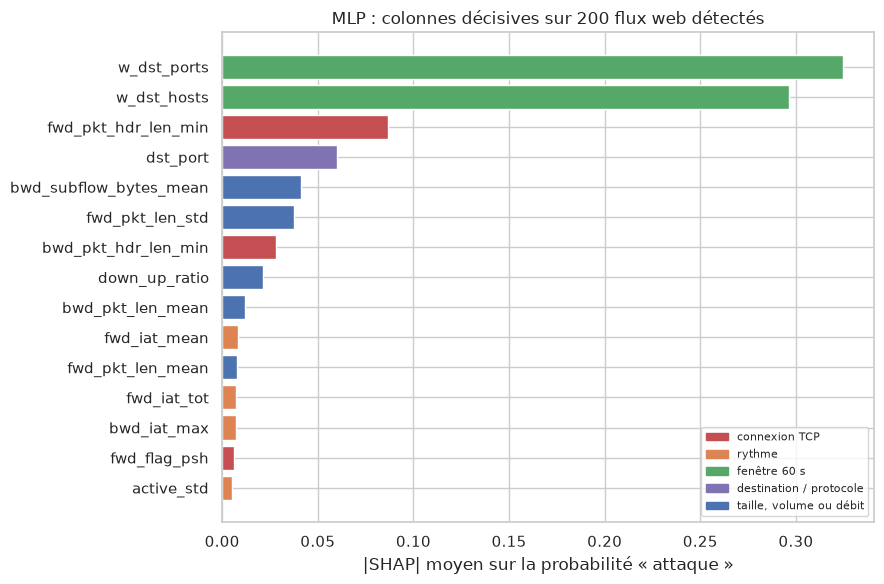

In [9]:
top = by_shap.head(15).iloc[::-1]
colors = {"connexion TCP": "#C44E52", "rythme": "#DD8452", "fenêtre 60 s": "#55A868",
          "destination / protocole": "#8172B3", "taille, volume ou débit": "#4C72B0"}

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["|SHAP| moyen"], color=[colors[kind] for kind in top["type"]])
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in colors.values()]
ax.legend(handles, colors.keys(), fontsize=8, loc="lower right")
ax.set_xlabel("|SHAP| moyen sur la probabilité « attaque »")
ax.set_title("MLP : colonnes décisives sur 200 flux web détectés")
fig.tight_layout()
fig.savefig(REPORTS / "04b_colonnes_decisives.png", dpi=150)
plt.show()

## 3. Réentraînement du MLP sans certains groupes de colonnes

Mêmes réglages que le MLP retenu : couches (128, 64), 20 époques, meilleure époque choisie sur val. 5 graines pour chaque variante, afin de comparer l'effet au hasard de l'entraînement.

La variante « sans top 15 » retire les 15 premières colonnes par permutation, quel que soit leur type. Elle dépend donc de test_inconnu : c'est un diagnostic, pas un modèle candidat.

Les résultats sont enregistrés après chaque entraînement, pour pouvoir reprendre sans tout recalculer si le calcul s'arrête.

In [10]:
RESULTS_FILE = MODELS / "04b_resultats.joblib"
if RESULTS_FILE.exists():
    results = load_model("04b_resultats")
else:
    results = {}

SEEDS = [0, 1, 2, 3, 4]
known = sorted(set(y_train))

Z_train = scaler.transform(signed_log(X_train))
Z_val = scaler.transform(signed_log(X_val))
Z_inconnu = scaler.transform(signed_log(X_inconnu))

variants = {
    "MLP complet": [],
    "sans connexion TCP": TCP_COLUMNS,
    "sans rythme": rhythm_columns(features),
    "sans TCP ni rythme": TCP_COLUMNS + rhythm_columns(features),
    "sans top 15": list(importance.head(15).index),
}

for name, removed in variants.items():
    kept = kept_positions(features, removed)
    for seed in SEEDS:
        key = ("mlp", name, seed)
        if key in results:
            continue
        model, history, best_epoch, duration = fit_mlp(Z_train[:, kept], y_train, Z_val[:, kept], y_val,
                                                       hidden=(128, 64), epochs=20, seed=seed)
        val_predictions = model.predict(Z_val[:, kept])
        row = {
            "variante": name, "graine": seed, "colonnes": len(kept), "meilleure époque": best_epoch,
            "macro-F1 val": macro_f1(y_val, val_predictions),
            "macro-F1 val sans heartbleed": macro_f1_without(y_val, val_predictions, known, "heartbleed"),
        }
        row.update(detection_by_class(y_inconnu, model.predict(Z_inconnu[:, kept])).to_dict())
        results[key] = row
        save_model(results, "04b_resultats")

mlp_rows = []
for key, row in results.items():
    if key[0] == "mlp":
        mlp_rows.append(row)
mlp_runs = pd.DataFrame(mlp_rows)
print("Vérification, graine 0 du MLP complet (macro-F1 val attendu : 0,9775) :",
      round(mlp_runs[(mlp_runs["variante"] == "MLP complet") & (mlp_runs["graine"] == 0)]["macro-F1 val"].iloc[0], 4))
mlp_runs.round(4)

Vérification, graine 0 du MLP complet (macro-F1 val attendu : 0,9775) : 0.9775


,variante,graine,colonnes,meilleure époque,macro-F1 val,macro-F1 val sans heartbleed,benign,bot,ddos,portscan,webattack_bruteforce,webattack_sql_injection,webattack_xss
0,MLP complet,0,78,9,0.9775,0.9743,0.0001,0.0,0.9994,0.0000,0.9434,0.0000,0.9970
1,MLP complet,1,78,6,0.9782,0.9751,0.0001,0.0,0.9991,0.0001,0.8956,0.0000,0.9939
2,MLP complet,2,78,1,0.9758,0.9723,0.0001,0.0,0.9998,0.0000,0.0787,0.5833,0.0303
3,MLP complet,3,78,7,0.9348,0.9731,0.0001,0.0,0.9979,0.0000,0.9419,0.0000,0.9939
4,MLP complet,4,78,4,0.9371,0.9757,0.0000,0.0,0.9987,0.0000,0.9051,0.0000,0.9470
5,sans connexion TCP,0,63,4,0.9371,0.9757,0.0001,0.0,0.9987,0.0001,0.9419,0.0000,0.9939
6,sans connexion TCP,1,63,6,0.9376,0.9763,0.0001,0.0,0.9993,0.0000,0.9941,0.1667,0.9955
7,sans connexion TCP,2,63,4,0.9383,0.9772,0.0000,0.0,0.9954,0.0000,0.9235,0.0000,0.9440
8,sans connexion TCP,3,63,6,0.9335,0.9716,0.0002,0.0,0.9986,0.0000,0.9419,0.0000,0.9939
9,sans connexion TCP,4,63,6,0.9378,0.9765,0.0002,0.0,0.9967,0.0000,0.9213,0.0000,0.9939


In [11]:
def mean_and_std(runs, group_column, columns):
    """Tableau « moyenne ± écart-type » pour chaque groupe."""
    table = {}
    for name in runs[group_column].unique():
        part = runs[runs[group_column] == name]
        cells = {}
        for col in columns:
            cells[col] = f"{part[col].mean():.3f} ± {part[col].std():.3f}"
        table[name] = cells
    return pd.DataFrame(table).T


columns = ["macro-F1 val sans heartbleed", "webattack_bruteforce", "webattack_xss", "webattack_sql_injection",
           "ddos", "portscan", "bot", BENIGN]
mean_and_std(mlp_runs, "variante", columns)

,macro-F1 val sans heartbleed,webattack_bruteforce,webattack_xss,webattack_sql_injection,ddos,portscan,bot,benign
MLP complet,0.974 ± 0.001,0.753 ± 0.378,0.792 ± 0.427,0.117 ± 0.261,0.999 ± 0.001,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
sans connexion TCP,0.975 ± 0.002,0.945 ± 0.029,0.984 ± 0.023,0.033 ± 0.075,0.998 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
sans rythme,0.971 ± 0.004,0.772 ± 0.403,0.799 ± 0.430,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
sans TCP ni rythme,0.971 ± 0.003,0.810 ± 0.296,0.820 ± 0.390,0.033 ± 0.075,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
sans top 15,0.969 ± 0.007,0.000 ± 0.000,0.011 ± 0.015,0.000 ± 0.000,0.986 ± 0.010,0.998 ± 0.001,0.000 ± 0.000,0.001 ± 0.001


In [12]:
# Application de la règle fixée à l'avance : moyenne sous 50 % ET baisse de plus de 2 écarts-types
baseline = mlp_runs[mlp_runs["variante"] == "MLP complet"]
rows = []
for name in variants:
    if name == "MLP complet":
        continue
    part = mlp_runs[mlp_runs["variante"] == name]
    for attack in ["webattack_bruteforce", "webattack_xss"]:
        base_mean = baseline[attack].mean()
        base_std = baseline[attack].std()
        new_mean = part[attack].mean()
        collapse = (new_mean < 0.5) and (new_mean < base_mean - 2 * base_std)
        rows.append({"variante": name, "attaque": attack, "complet": round(base_mean, 3),
                     "sans ces colonnes": round(new_mean, 3), "chute": collapse})
pd.DataFrame(rows)

,variante,attaque,complet,sans ces colonnes,chute
0,sans connexion TCP,webattack_bruteforce,0.753,0.945,False
1,sans connexion TCP,webattack_xss,0.792,0.984,False
2,sans rythme,webattack_bruteforce,0.753,0.772,False
3,sans rythme,webattack_xss,0.792,0.799,False
4,sans TCP ni rythme,webattack_bruteforce,0.753,0.810,False
5,sans TCP ni rythme,webattack_xss,0.792,0.820,False
6,sans top 15,webattack_bruteforce,0.753,0.000,False
7,sans top 15,webattack_xss,0.792,0.011,False


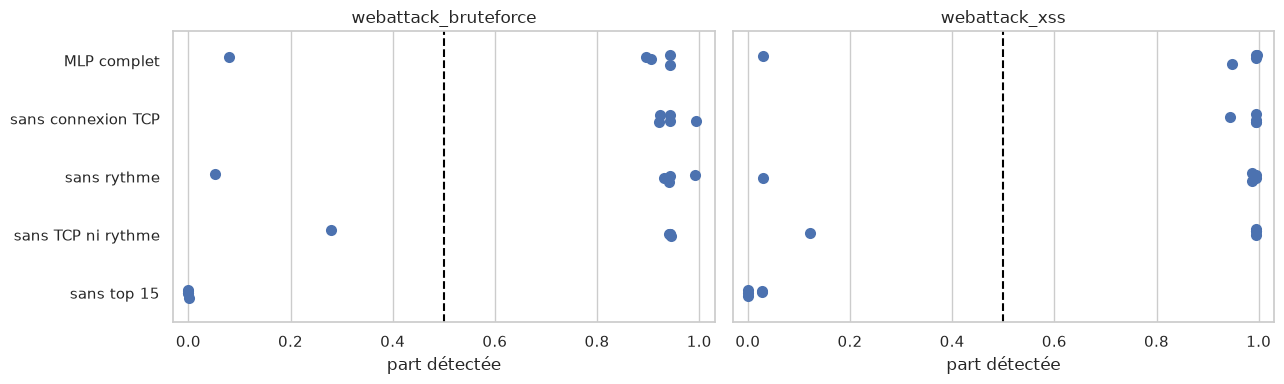

In [13]:
# Détection de chaque graine : la moyenne peut cacher des résultats très dispersés
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, attack in zip(axes, ["webattack_bruteforce", "webattack_xss"]):
    sns.stripplot(data=mlp_runs, y="variante", x=attack, order=list(variants), size=8, color="#4C72B0", ax=ax)
    ax.axvline(0.5, color="black", linestyle="--")
    ax.set_xlim(-0.03, 1.03)
    ax.set_xlabel("part détectée")
    ax.set_ylabel("")
    ax.set_title(attack)
fig.tight_layout()
fig.savefig(REPORTS / "04b_mlp_sans_colonnes.png", dpi=150)
plt.show()

## 4. Stabilité de l'autoencodeur

Pour chaque goulot et chaque graine : mêmes entraînement et préparation que dans le notebook 04, seuil fixé sur le benign de val, mesure sur test_inconnu.

In [14]:
X_train_benign = X_train[y_train == BENIGN]
X_val_benign = X_val[y_val == BENIGN]

ae_scaler = StandardScaler()
ae_scaler.fit(signed_log(X_train_benign))
Z_train_benign = ae_scaler.transform(signed_log(X_train_benign))
Z_val_benign = ae_scaler.transform(signed_log(X_val_benign))
Z_val_ae = ae_scaler.transform(signed_log(X_val))
Z_inconnu_ae = ae_scaler.transform(signed_log(X_inconnu))

for latent in [8, 16, 32]:
    for seed in SEEDS:
        key = ("ae", latent, seed)
        if key in results:
            continue
        model, history, best_epoch, duration = fit_autoencoder(Z_train_benign, Z_val_benign, latent_size=latent, seed=seed)
        val_scores = reconstruction_error(model, Z_val_ae)
        threshold = threshold_from_benign(val_scores, y_val)
        val_table = detection_table(y_val, val_scores, threshold)
        test_table = detection_table(y_inconnu, reconstruction_error(model, Z_inconnu_ae), threshold)

        row = {"goulot": latent, "graine": seed, "meilleure époque": best_epoch,
               "perte val": history["perte val"].min(), "rappel moyen val": mean_attack_recall(val_table)}
        row.update(test_table["part détectée"].to_dict())
        results[key] = row
        save_model(results, "04b_resultats")

ae_rows = []
for key, row in results.items():
    if key[0] == "ae":
        ae_rows.append(row)
ae_runs = pd.DataFrame(ae_rows)
print("Vérification, goulot 8 graine 0 (rappel moyen val attendu : 0,8739) :",
      round(ae_runs[(ae_runs["goulot"] == 8) & (ae_runs["graine"] == 0)]["rappel moyen val"].iloc[0], 4))
ae_runs.round(4)

Vérification, goulot 8 graine 0 (rappel moyen val attendu : 0,8739) : 0.8739


,goulot,graine,meilleure époque,perte val,rappel moyen val,benign,bot,ddos,portscan,webattack_bruteforce,webattack_sql_injection,webattack_xss
0,8,0,20,0.0206,0.8739,0.0153,0.7347,1.0000,1.0000,0.0537,0.0,0.0272
1,8,1,20,0.0227,0.9201,0.0124,0.2707,0.9999,1.0000,0.0529,0.0,0.0272
2,8,2,20,0.0187,0.7462,0.0132,0.2163,1.0000,0.9998,0.0478,0.0,0.0272
3,8,3,20,0.0197,0.8876,0.0144,0.9429,1.0000,1.0000,0.0537,0.0,0.0272
4,8,4,20,0.0204,0.9179,0.0143,0.2354,0.9997,0.9994,0.0537,0.0,0.0272
5,16,0,20,0.0071,0.6769,0.0127,0.0585,1.0000,1.0000,0.0000,0.0,0.0272
6,16,1,18,0.0077,0.6611,0.0129,0.0599,1.0000,1.0000,0.0000,0.0,0.0272
7,16,2,20,0.0059,0.9767,0.0131,0.0653,1.0000,1.0000,0.0000,0.0,0.0272
8,16,3,20,0.0072,0.6499,0.0127,0.0694,1.0000,1.0000,0.0000,0.0,0.0272
9,16,4,20,0.0066,0.6340,0.0125,0.0599,1.0000,1.0000,0.0000,0.0,0.0000


In [15]:
columns = ["rappel moyen val", "perte val", "bot", "webattack_bruteforce", "webattack_xss", "webattack_sql_injection",
           "ddos", "portscan", BENIGN]
mean_and_std(ae_runs, "goulot", columns)

,rappel moyen val,perte val,bot,webattack_bruteforce,webattack_xss,webattack_sql_injection,ddos,portscan,benign
8,0.869 ± 0.072,0.020 ± 0.001,0.480 ± 0.336,0.052 ± 0.003,0.027 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.014 ± 0.001
16,0.720 ± 0.145,0.007 ± 0.001,0.063 ± 0.005,0.000 ± 0.000,0.022 ± 0.012,0.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.013 ± 0.000
32,0.579 ± 0.156,0.002 ± 0.000,0.060 ± 0.000,0.010 ± 0.022,0.026 ± 0.002,0.000 ± 0.000,0.987 ± 0.029,1.000 ± 0.000,0.012 ± 0.000


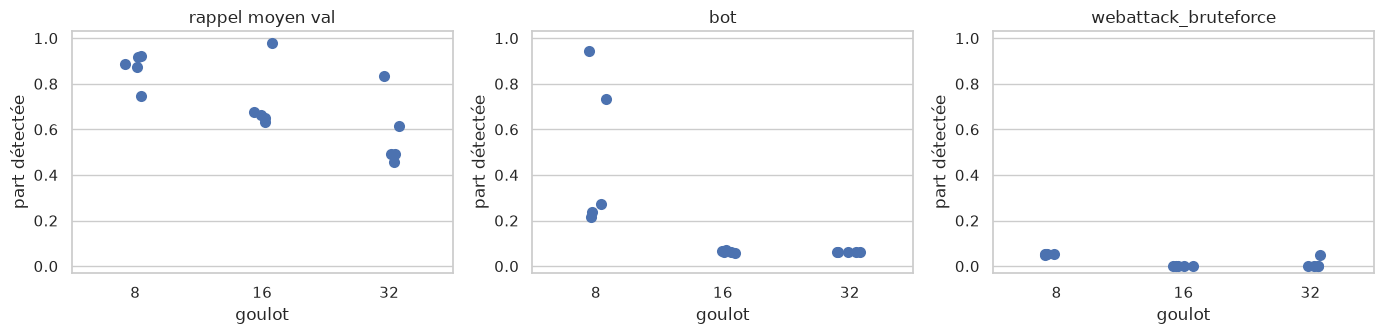

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["rappel moyen val", "bot", "webattack_bruteforce"]):
    sns.stripplot(data=ae_runs, x="goulot", y=col, size=8, color="#4C72B0", ax=ax)
    ax.set_ylim(-0.03, 1.03)
    ax.set_title(col)
    ax.set_ylabel("part détectée")
fig.tight_layout()
fig.savefig(REPORTS / "04b_stabilite_autoencodeur.png", dpi=150)
plt.show()

## 5. Tests ajoutés après coup

Ces trois tests n'étaient **pas** prévus au départ. Ils viennent des résultats ci-dessus, vus sur test_inconnu : ce sont des diagnostics, et ils ne changent aucun modèle.

1. **Variante « sans fenêtres 60 s »** : SHAP donne 63 % de l'importance à ces colonnes, et aucune variante prévue ne les retirait seules.
2. **Le benign au même profil** : le MLP signale-t-il le trafic normal qui, lui aussi, ne contacte qu'une machine et qu'un port par minute ?
3. **Suivi époque par époque** : les échecs de détection semblent venir de modèles arrêtés à l'époque 1, choisie sur un macro-F1 sensible aux 2 flux heartbleed.

In [17]:
# 1. Sans les 4 colonnes de fenêtre : mêmes réglages, 5 graines
window_columns = ["w_conn", "w_dst_ports", "w_dst_hosts", "w_rst_rate"]
kept = kept_positions(features, window_columns)
for seed in SEEDS:
    key = ("mlp_fenetres", seed)
    if key in results:
        continue
    model, history, best_epoch, duration = fit_mlp(Z_train[:, kept], y_train, Z_val[:, kept], y_val,
                                                   hidden=(128, 64), epochs=20, seed=seed)
    val_predictions = model.predict(Z_val[:, kept])
    row = {"variante": "sans fenêtres 60 s", "graine": seed, "colonnes": len(kept), "meilleure époque": best_epoch,
           "macro-F1 val": macro_f1(y_val, val_predictions),
           "macro-F1 val sans heartbleed": macro_f1_without(y_val, val_predictions, known, "heartbleed")}
    row.update(detection_by_class(y_inconnu, model.predict(Z_inconnu[:, kept])).to_dict())
    results[key] = row
    save_model(results, "04b_resultats")

window_rows = []
for seed in SEEDS:
    window_rows.append(results[("mlp_fenetres", seed)])
window_runs = pd.DataFrame(window_rows)
show = ["graine", "meilleure époque", "macro-F1 val sans heartbleed", "webattack_bruteforce", "webattack_xss",
        "webattack_sql_injection", "ddos", "portscan", "bot", BENIGN]
window_runs[show].round(4)

,graine,meilleure époque,macro-F1 val sans heartbleed,webattack_bruteforce,webattack_xss,webattack_sql_injection,ddos,portscan,bot,benign
0,0,14,0.9731,0.0007,0.0015,0.6667,0.9997,0.0028,0.0,0.0002
1,1,17,0.9729,0.0029,0.0287,0.8333,0.9996,0.0032,0.0,0.0002
2,2,15,0.9744,0.0000,0.0287,0.4167,0.9998,0.0063,0.0,0.0001
3,3,17,0.9744,0.0007,0.0287,0.8333,0.9997,0.0071,0.0,0.0003
4,4,20,0.9727,0.0000,0.0287,0.2500,0.9998,0.0043,0.0,0.0001


In [18]:
# 2. Part des flux au profil « 1 machine et 1 port par minute », et alertes du MLP retenu sur ces flux
w_hosts = features.index("w_dst_hosts")
w_ports = features.index("w_dst_ports")
one_target_train = (X_train[:, w_hosts] == 1) & (X_train[:, w_ports] == 1)
one_target_inconnu = (X_inconnu[:, w_hosts] == 1) & (X_inconnu[:, w_ports] == 1)

print("Benign de train avec ce profil :", one_target_train[y_train == BENIGN].sum(), "sur", (y_train == BENIGN).sum())
print("Attaques de train avec ce profil :", one_target_train[y_train != BENIGN].sum(), "sur", (y_train != BENIGN).sum())

rows = []
for name in np.unique(y_inconnu):
    is_class = y_inconnu == name
    with_profile = is_class & one_target_inconnu
    without_profile = is_class & ~one_target_inconnu
    row = {"classe": name, "flux": is_class.sum(), "avec ce profil": with_profile.sum(),
           "alertes (avec profil)": (mlp_inconnu[with_profile] != BENIGN).sum()}
    if with_profile.sum() > 0:
        row["part en alerte (avec profil)"] = round((mlp_inconnu[with_profile] != BENIGN).mean(), 4)
    if without_profile.sum() > 0:
        row["part en alerte (sans profil)"] = round((mlp_inconnu[without_profile] != BENIGN).mean(), 4)
    rows.append(row)
pd.DataFrame(rows).set_index("classe")

Benign de train avec ce profil : 61782 sur 699151
Attaques de train avec ce profil : 128283 sur 128283


,flux,avec ce profil,alertes (avec profil),part en alerte (avec profil),part en alerte (sans profil)
classe,,,,,
benign,396886,32620,28,0.0009,0.000
bot,735,32,0,0.0000,0.000
ddos,95683,94614,94614,1.0000,0.942
portscan,160106,7,4,0.5714,0.000
webattack_bruteforce,1360,1360,1283,0.9434,NaN
webattack_sql_injection,12,12,0,0.0000,NaN
webattack_xss,661,661,659,0.9970,NaN


In [19]:
# 2 bis. Le benign au même profil : vient-il de la machine de l'attaquant ?
benign_profile = (y_inconnu == BENIGN) & one_target_inconnu
source_counts = pd.Series(ip_inconnu[benign_profile]).value_counts()
print("Machines sources différentes :", len(source_counts))
print("Part venant de", ATTACKER, ":", round((ip_inconnu[benign_profile] == ATTACKER).mean(), 4))
source_counts.head(5)

Machines sources différentes : 28
Part venant de 172.16.0.1 : 0.0013


192.168.10.3     30769
192.168.10.51      560
192.168.10.8       185
192.168.10.15      159
192.168.10.9       122
Name: count, dtype: int64

In [20]:
# 3. MLP complet suivi à chaque époque, 5 graines (observation seulement)
X_web = Z_inconnu[is_web]
y_web = y_inconnu[is_web]
for seed in SEEDS:
    key = ("trace", seed)
    if key in results:
        continue
    results[key] = trace_mlp_epochs(Z_train, y_train, Z_val, y_val, X_web, y_web, known, seed=seed)
    save_model(results, "04b_resultats")

trace_rows = []
for seed in SEEDS:
    trace_rows.extend(results[("trace", seed)])
trace = pd.DataFrame(trace_rows)

# Pour chaque graine, détection selon la règle d'arrêt : macro-F1 avec heartbleed, sans heartbleed, ou époque 20
rows = []
for seed in SEEDS:
    part = trace[trace["graine"] == seed]
    choices = {
        "macro-F1 val (protocole)": part.loc[part["macro-F1 val"].idxmax()],
        "macro-F1 val sans heartbleed": part.loc[part["sans heartbleed"].idxmax()],
        "époque 20": part.iloc[-1],
    }
    for rule, chosen in choices.items():
        rows.append({"graine": seed, "règle d'arrêt": rule, "époque": int(chosen["époque"]),
                     "bruteforce": round(chosen["webattack_bruteforce"], 3), "xss": round(chosen["webattack_xss"], 3)})
stopping = pd.DataFrame(rows)
stopping.pivot(index="graine", columns="règle d'arrêt", values=["époque", "bruteforce", "xss"])

époque                                         \
règle d'arrêt macro-F1 val (protocole) macro-F1 val sans heartbleed époque 20   
graine                                                                          
0                                  9.0                          6.0      20.0   
1                                  6.0                          6.0      20.0   
2                                  1.0                         13.0      20.0   
3                                  7.0                          7.0      20.0   
4                                  4.0                          4.0      20.0   

                            bruteforce                                         \
règle d'arrêt macro-F1 val (protocole) macro-F1 val sans heartbleed époque 20   
graine                                                                          
0                                0.943                        0.932     0.943   
1                                0.896                        0.896     0.999   
2                                0.079                        0.890     0.889   
3                                0.942                        0.942     0.938   
4                                0.905                        0.905     0.940   

                                   xss                                         
règle d'arrêt macro-F1 val (protocole) macro-F1 val sans heartbleed époque 20  
graine                                                                         
0                                0.997                        0.982     0.997  
1                                0.994                        0.994     0.998  
2                                0.030                        0.994     0.997  
3                                0.994                        0.994     0.997  
4                                0.947                        0.947     0.994

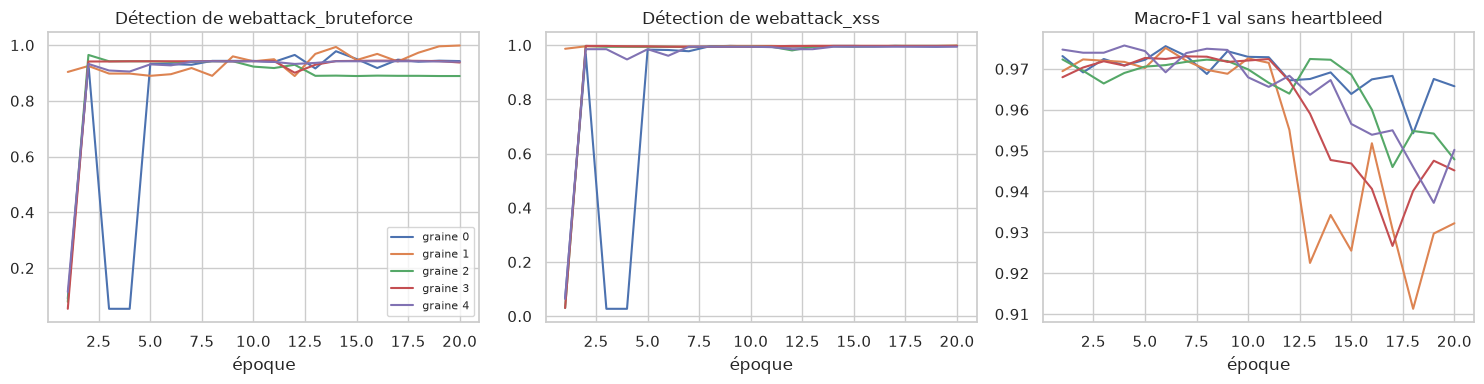

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for seed in SEEDS:
    part = trace[trace["graine"] == seed]
    axes[0].plot(part["époque"], part["webattack_bruteforce"], label="graine " + str(seed))
    axes[1].plot(part["époque"], part["webattack_xss"])
    axes[2].plot(part["époque"], part["sans heartbleed"])
axes[0].set_title("Détection de webattack_bruteforce")
axes[1].set_title("Détection de webattack_xss")
axes[2].set_title("Macro-F1 val sans heartbleed")
axes[0].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("époque")
fig.tight_layout()
fig.savefig(REPORTS / "04b_mlp_par_epoque.png", dpi=150)
plt.show()

## Observations

1. **Le MLP ne s'appuie pas sur la pile TCP ni sur le rythme.** Sans ces colonnes, la détection des attaques web reste élevée sur la plupart des graines. Mélanger les colonnes TCP laisse 98,8 % de détection, et mélanger celles de rythme 93,2 %.
2. **Il s'appuie sur les fenêtres de 60 s.** `w_dst_ports` et `w_dst_hosts` portent 63 % de l'importance SHAP. Sans les 4 colonnes de fenêtre (test ajouté après coup), la détection tombe sur les **5 graines** : bruteforce 0,1 % en moyenne, XSS 2,3 %. Le mélange de ces colonnes laisse 54,8 %, mais c'est proche de la perte maximale : la moitié des flux du mélange sont des flux web, qui gardent donc souvent une valeur web.
3. **Le profil en cause : « 1 machine et 1 port par minute ».** **100 % des attaques de train (128 283 sur 128 283) ont ce profil**, contre 8,8 % du benign de train. 100 % des flux web de test_inconnu l'ont aussi.
4. **Ce profil ne suffit pas à déclencher une alerte.** 32 620 flux benign de test_inconnu l'ont, venus de 28 machines, et seuls 28 sont signalés (0,09 %). Le MLP combine donc ce profil avec d'autres colonnes. Il ne dit pas simplement « une seule cible = attaque ».
5. **Verdict sur l'hypothèse.** La forme précise de l'hypothèse (pile TCP, rythme des outils) n'est pas soutenue. Mais il existe bien une dépendance forte à une propriété du scénario : dans LYCOS, chaque attaque connue a été jouée depuis une source qui ne visait qu'une machine et un port à la fois. Le chiffre de 94 à 99,7 % ne montre donc pas que le MLP reconnaît les attaques web en général. Il montre qu'il reconnaît un flux qui ressemble à une attaque jouée dans ces conditions. Sur le benign de `172.16.0.1`, le taux d'alerte est de 6,7 %, contre 0,003 % ailleurs : c'est compatible avec cette lecture, mais ces flux partagent leurs fenêtres avec les attaques de la même minute. LYCOS ne permet pas de séparer davantage la machine, le scénario et le comportement, puisque toutes les attaques web viennent d'une seule source.
6. **Sans les fenêtres, le MLP se comporte comme un supervisé classique** face à des attaques web inconnues (0,1 à 2,3 %), un ordre de grandeur cohérent avec la fourchette de 1 à 19 % citée par Bedis (Xu et Liu 2025, référence non vérifiée ici).
7. **L'instabilité venait surtout de l'arrêt à l'époque 1, pas du hasard de l'initialisation.** Dans le suivi époque par époque, la détection est très basse à l'époque 1 pour 4 graines sur 5, puis se stabilise à partir de l'époque 2 à 5. La graine 2 s'arrêtait à l'époque 1 parce que le macro-F1 y gagne 0,04 quand les 2 flux heartbleed sont réussis (0,976 contre environ 0,93 ensuite).
8. **Avec un arrêt sans heartbleed, les 5 graines sont stables :** bruteforce 91,3 % ± 2,3, XSS 98,2 % ± 2,0. Ce n'est pas le protocole fixé, et ce résultat est vu sur test_inconnu : il sert à comprendre, pas à choisir. Le « sans connexion TCP » qui paraissait meilleur (95 % ± 3) s'explique de la même façon : aucune de ses graines ne s'arrête à l'époque 1.
9. **Ma règle fixée à l'avance a mal fonctionné.** Elle répond « pas de chute », même pour le top 15 (de 75 % à 0 %), parce que l'écart-type du MLP complet (0,38) met le seuil de 2 écarts-types sous zéro. Elle est conservée telle quelle dans le notebook. La lecture graine par graine s'y substitue, en le disant clairement.
10. **Sans le top 15, le portscan passe d'environ 0 % à 99,8 %.** Ce n'est pas dû aux fenêtres : sans elles seules, il reste à 0,5 %. La cause n'est donc pas identifiée. La variante dépend de test_inconnu : ce n'est pas une amélioration utilisable.
11. **Sans les fenêtres, le macro-F1 sur val ne baisse pas** (0,973 à 0,974, sans heartbleed, soit presque autant que le MLP complet). Elles ne sont donc pas nécessaires pour les attaques connues au niveau de la val, mais elles déterminent ce que le MLP fait face aux attaques web.
12. **Autoencodeur sur 5 graines (goulot 8).** Portscan et DDoS restent à environ 100 %. Les attaques web restent basses (5,2 % et 2,7 %). **Bot : 48,0 % ± 33,6**, de 21,6 % à 94,3 % selon la graine. Le 73,5 % du notebook 04 ne doit donc pas être présenté seul. Le rappel moyen sur val confirme le goulot 8 (0,869 contre 0,720 et 0,579). Sa dispersion reste forte (0,746 à 0,920).
13. **Non testé.** Le RF et l'autoencodeur utilisent aussi ces fenêtres : on ne sait pas combien leurs détections en dépendent. Rien ne montre non plus comment ces modèles se comporteraient sur un autre réseau.